# Velvetfruit vouchers: price & implied-volatility analysis

Uses the helpers in `prosperity_analysis.py`.

In [1]:
import sys
sys.path.insert(0, './')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8')
%matplotlib inline

import importlib
import prosperity_analysis
importlib.reload(prosperity_analysis)

from prosperity_analysis import *

import plotly.io as pio
pio.renderers.default = "notebook_connected"

from prosperity_analysis import (
    load_prices, load_trades, debug_files,
    get_products, enrich, enrich_spread, compute_spread,
    plot_price_evolution, plot_bid_ask_spread, plot_zscore_velocity,
    plot_spread, plot_spread_zscore, spread_stats,
    compare_editions, compare_spread_editions,
    overview, halfday_fair_values, match_product_across_editions,
)


In [6]:
# ── Folder layout ───────────────────────────────────────────────
#   Prices/                  ← current year files (auto-detected)
#   Prices/P1/               ← Prosperity 1
#   Prices/P2/               ← Prosperity 2
#   Prices/P3/               ← Prosperity 3
# ────────────────────────────────────────────────────────────────

# If anything fails, uncomment this to see exactly what files are found:
# debug_files("Prices")

# Current year
df = load_prices("DATA_DIR")
df_trade = load_trades("DATA_DIR")   # returns empty DataFrame if no trade files found

# Previous years (uncomment as you add folders)
# df_p1 = load_prices("Prices", edition="P1")
# df_p2 = load_prices("Prices", edition="P2")
df_p3 = load_prices("Prices", edition="P3")

print("Products this year:", get_products(df))
print(f"Price rows : {len(df):,}")
print(f"Trade rows : {len(df_trade):,}")


Products this year: ['HYDROGEL_PACK', 'VELVETFRUIT_EXTRACT', 'VEV_4000', 'VEV_4500', 'VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500', 'VEV_6000', 'VEV_6500']
Price rows : 480,000
Trade rows : 5,589


Products   : ['HYDROGEL_PACK', 'VELVETFRUIT_EXTRACT', 'VEV_4000', 'VEV_4500', 'VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500', 'VEV_6000', 'VEV_6500']
Days loaded: 4 file(s)
Rows       : 480,000
Timestamps : 0 → 3,999,900

HYDROGEL_PACK


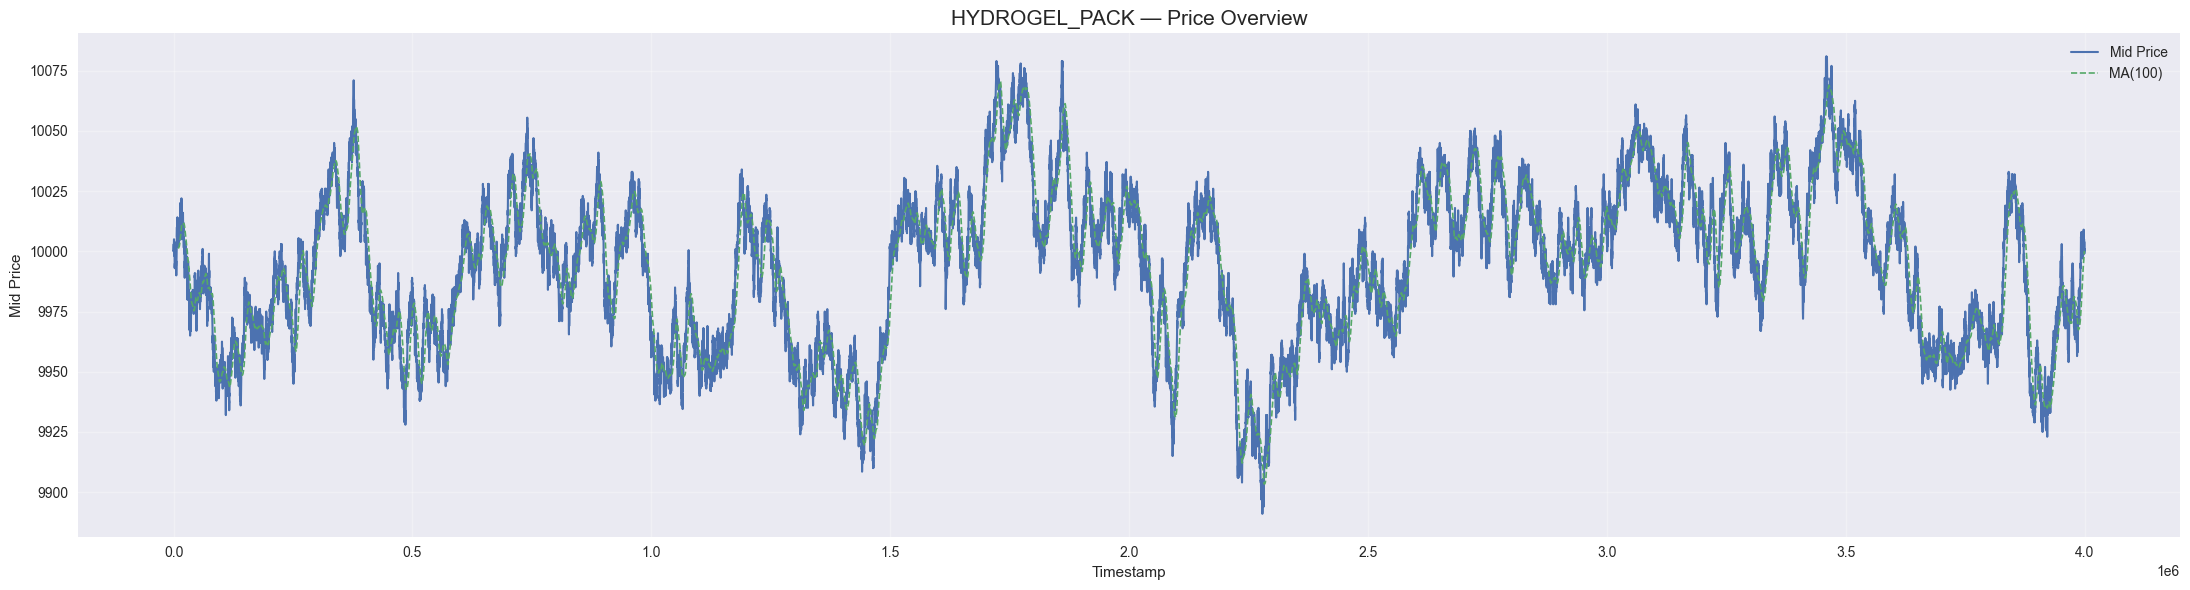

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,9990.96,9983.11,9998.81
0,first half,9984.7,9976.85,9992.55
0,second half,9997.23,9989.37,10005.08
1,full day,9992.06,9984.19,9999.92
1,first half,9962.8,9954.95,9970.65
1,second half,10021.31,10013.43,10029.18
2,full day,9989.4,9981.54,9997.27
2,first half,9971.29,9963.43,9979.15
2,second half,10007.52,9999.65,10015.39
3,full day,10002.5,9994.64,10010.37



VELVETFRUIT_EXTRACT


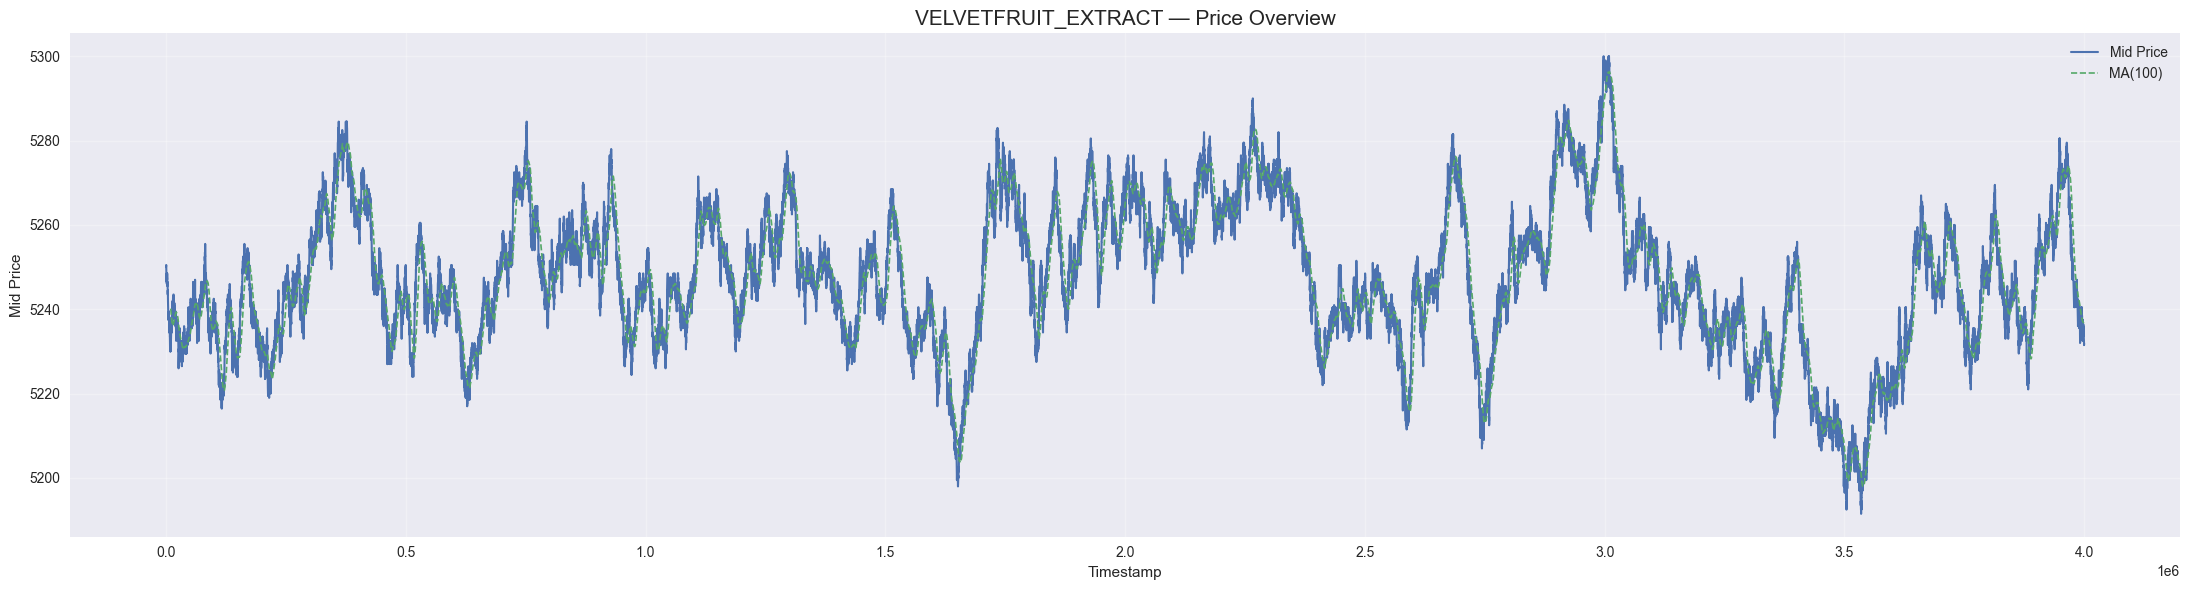

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,5246.51,5244.01,5249.01
0,first half,5245.23,5242.74,5247.73
0,second half,5247.79,5245.29,5250.28
1,full day,5248.39,5245.9,5250.88
1,first half,5248.36,5245.87,5250.84
1,second half,5248.43,5245.93,5250.93
2,full day,5255.39,5252.9,5257.89
2,first half,5259.07,5256.58,5261.56
2,second half,5251.72,5249.22,5254.21
3,full day,5239.16,5236.67,5241.65



VEV_4000


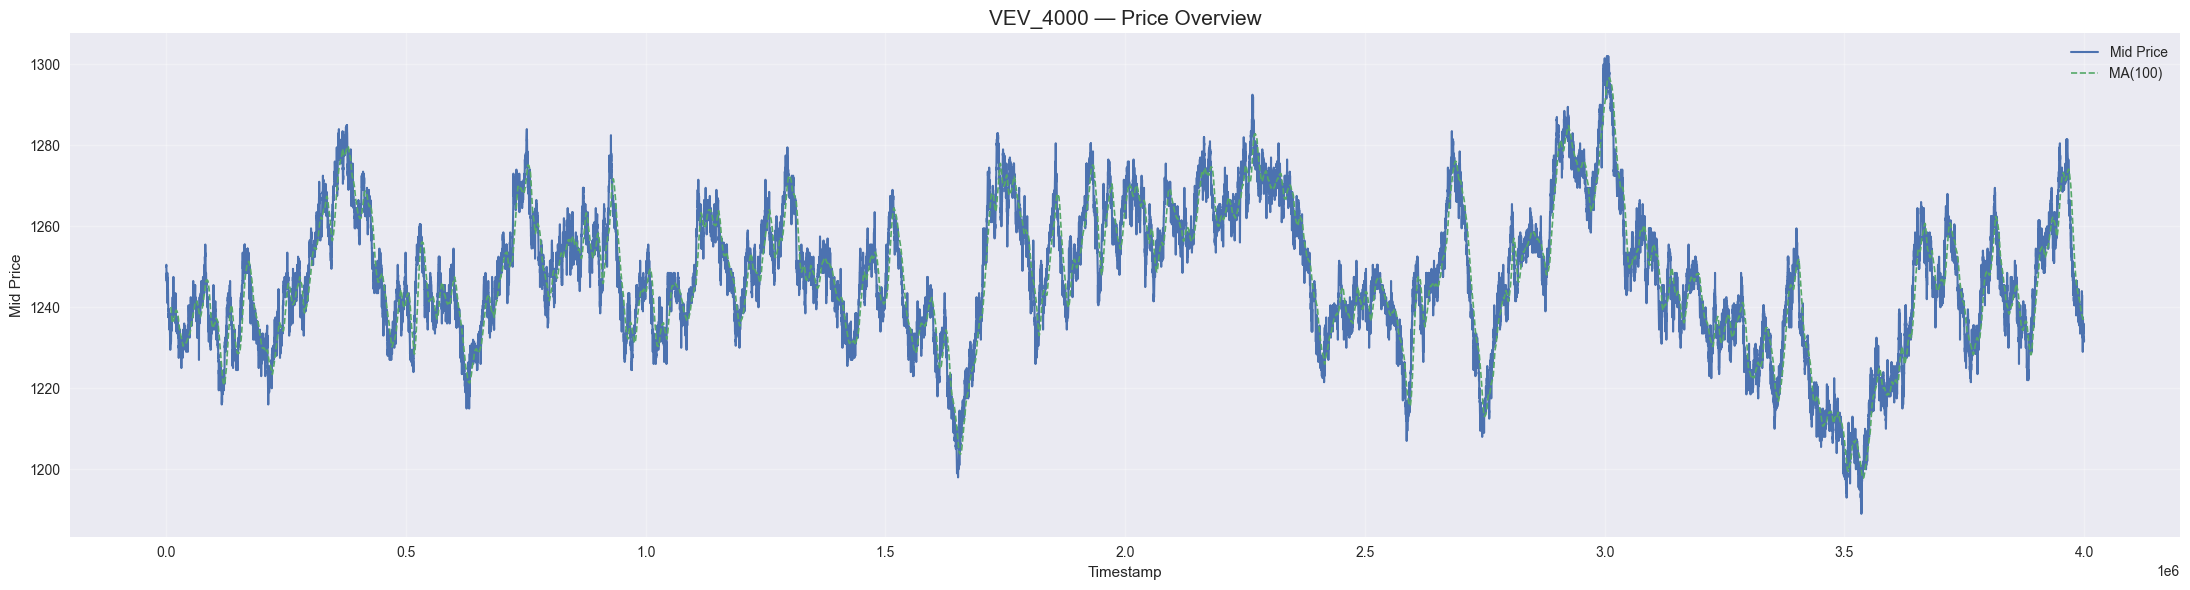

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,1246.52,1236.14,1256.91
0,first half,1245.24,1234.87,1255.62
0,second half,1247.8,1237.41,1258.2
1,full day,1248.41,1238.02,1258.8
1,first half,1248.38,1237.99,1258.78
1,second half,1248.43,1238.05,1258.82
2,full day,1255.4,1244.95,1265.85
2,first half,1259.07,1248.6,1269.54
2,second half,1251.72,1241.3,1262.15
3,full day,1239.16,1228.87,1249.46



VEV_4500


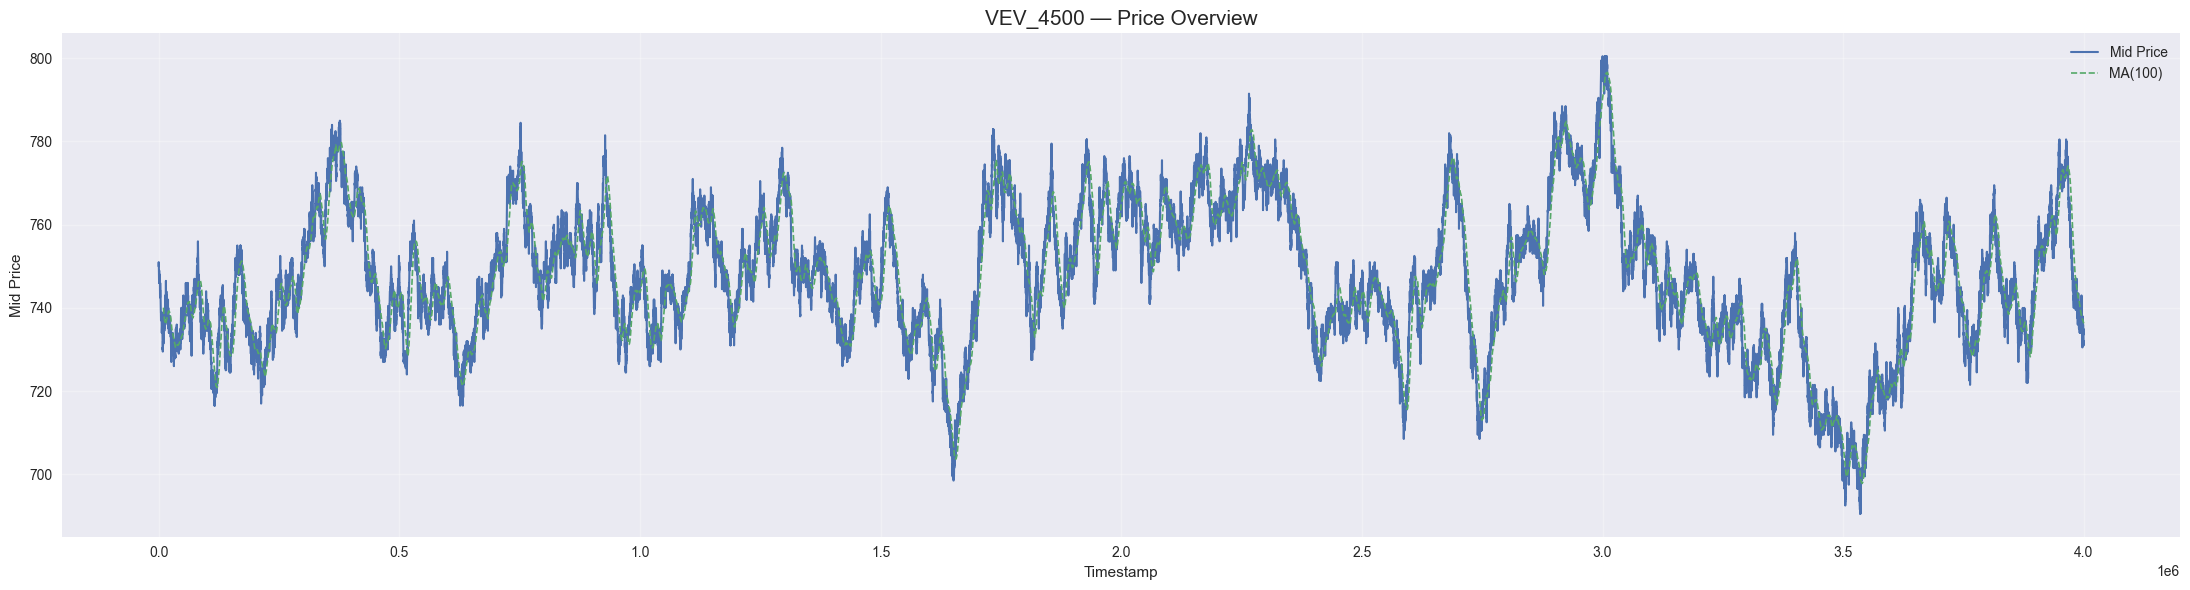

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,746.52,738.63,754.41
0,first half,745.24,737.36,753.12
0,second half,747.8,739.9,755.71
1,full day,748.41,740.5,756.31
1,first half,748.38,740.47,756.29
1,second half,748.43,740.53,756.34
2,full day,755.4,747.42,763.38
2,first half,759.07,751.06,767.09
2,second half,751.73,743.78,759.68
3,full day,739.16,731.36,746.97



VEV_5000


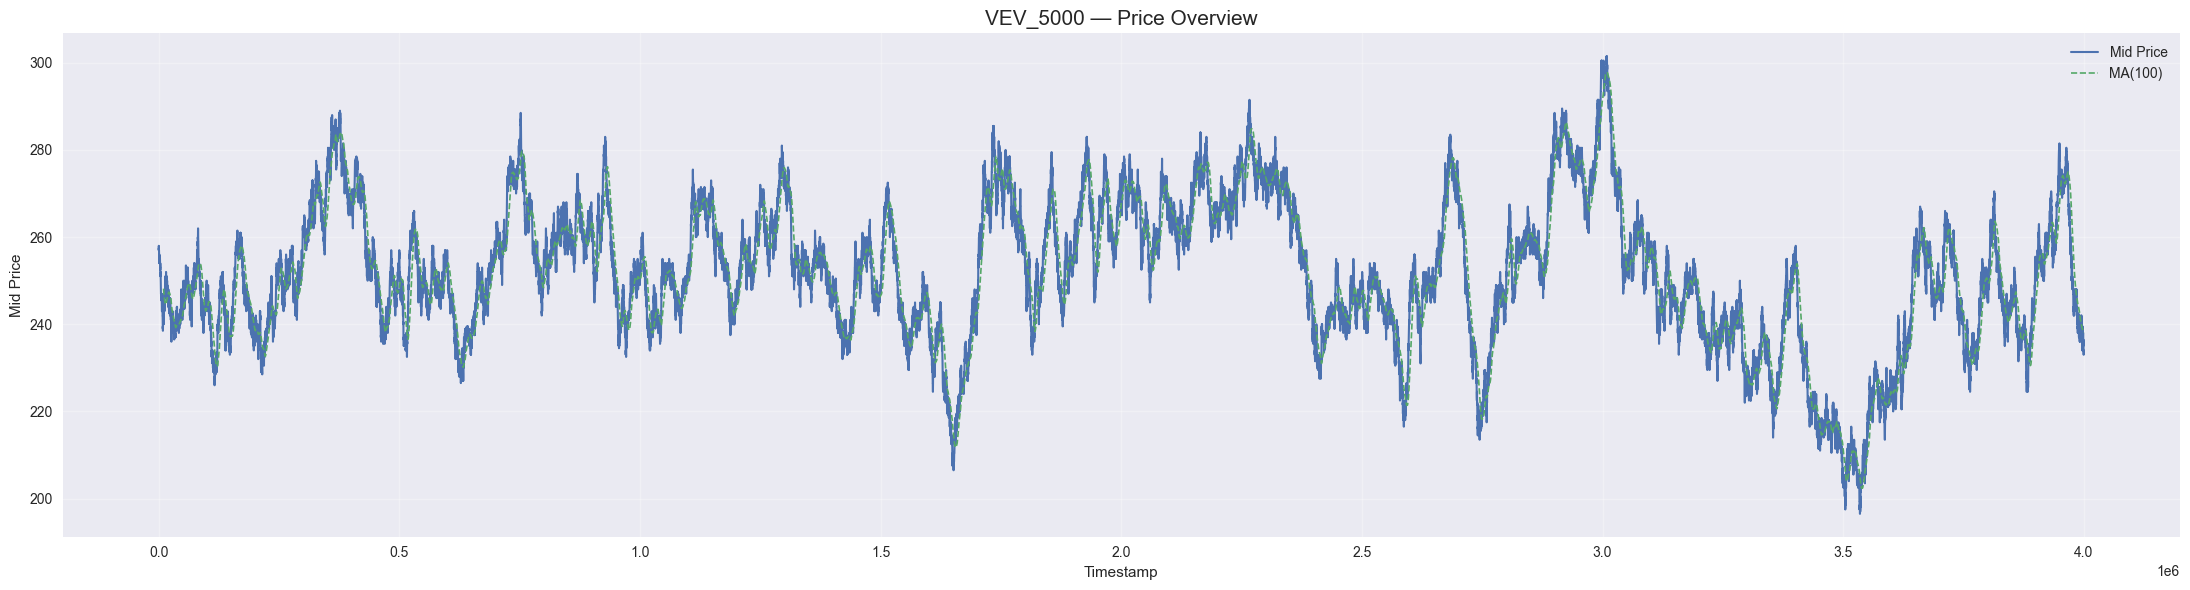

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,253.26,250.26,256.26
0,first half,252.38,249.38,255.37
0,second half,254.14,251.13,257.15
1,full day,253.26,250.26,256.27
1,first half,253.68,250.67,256.69
1,second half,252.85,249.85,255.85
2,full day,258.54,255.48,261.6
2,first half,262.25,259.15,265.34
2,second half,254.84,251.82,257.87
3,full day,241.63,238.74,244.51



VEV_5100


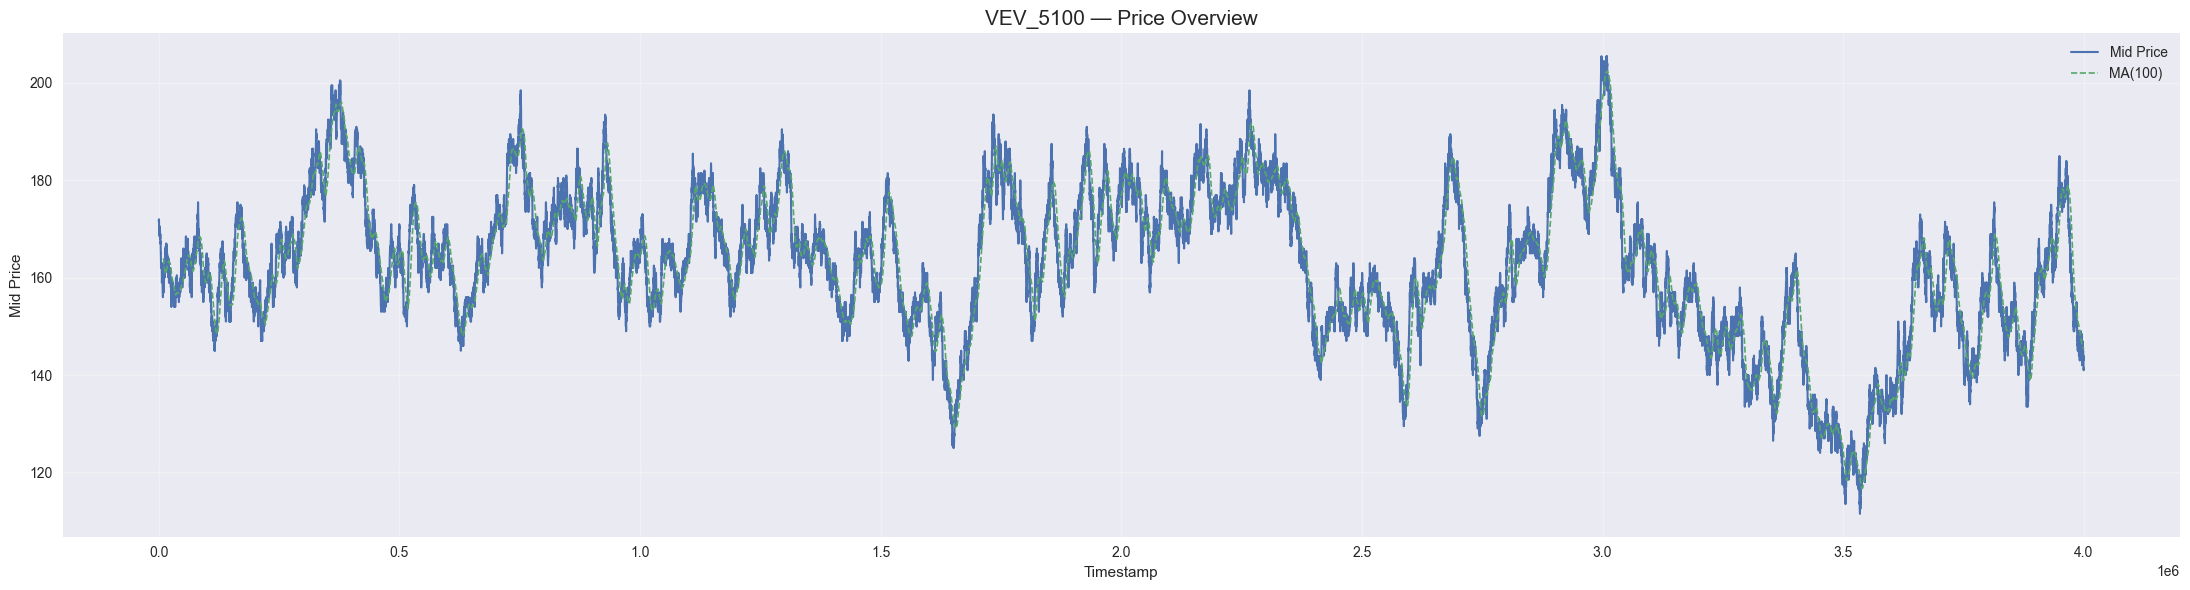

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,168.11,165.95,170.27
0,first half,167.66,165.51,169.82
0,second half,168.55,166.39,170.71
1,full day,164.98,162.85,167.11
1,first half,166.04,163.9,168.19
1,second half,163.92,161.81,166.04
2,full day,167.33,165.17,169.48
2,first half,171.1,168.9,173.29
2,second half,163.56,161.44,165.67
3,full day,150.28,148.3,152.26



VEV_5200


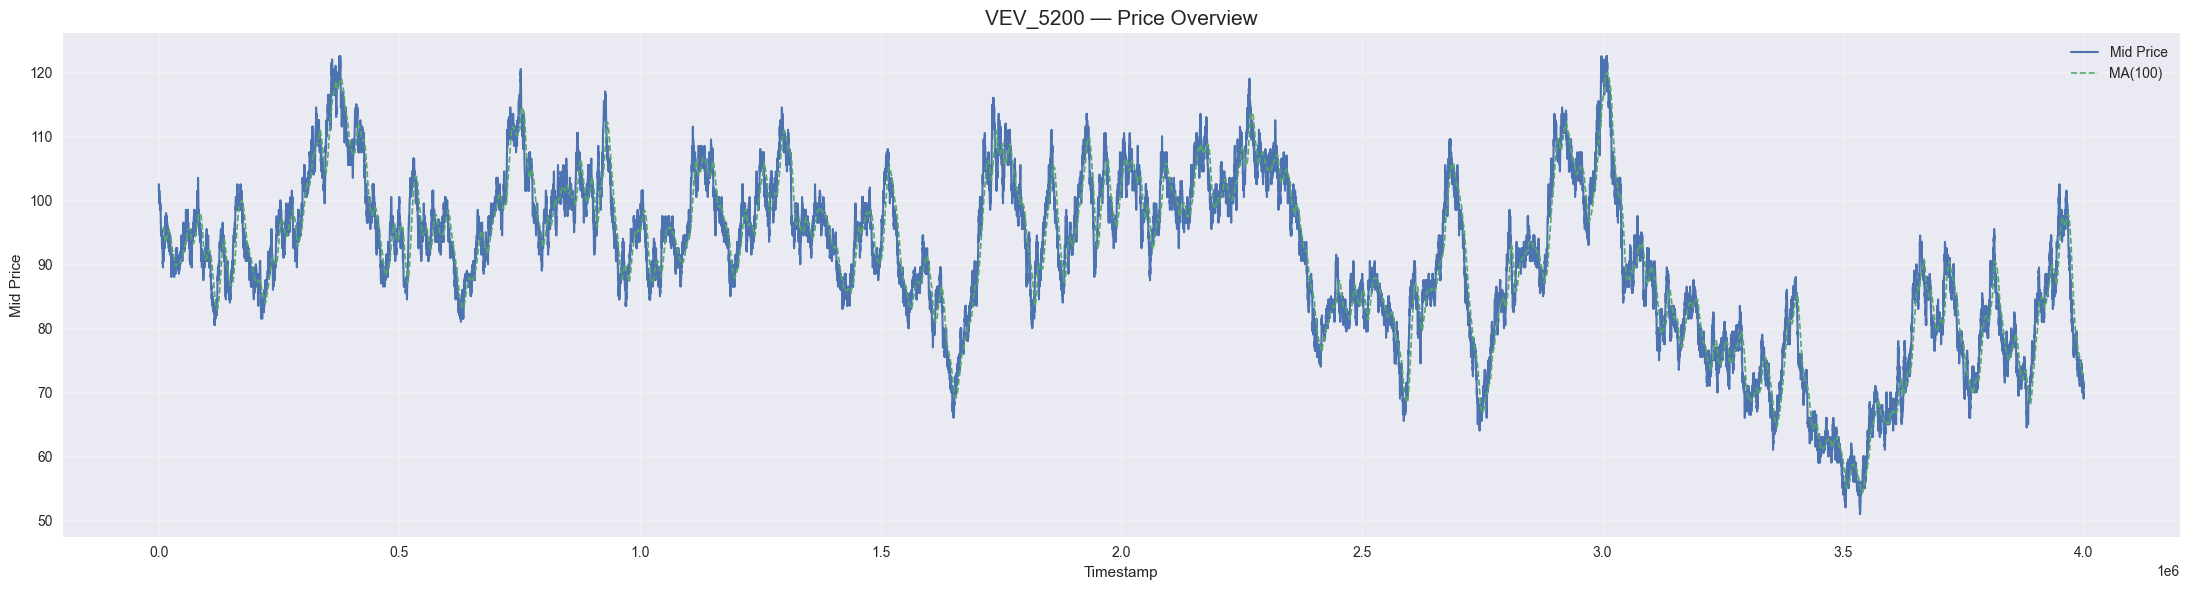

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,97.47,96.01,98.93
0,first half,97.25,95.79,98.71
0,second half,97.7,96.23,99.16
1,full day,95.13,93.69,96.57
1,first half,96.37,94.92,97.82
1,second half,93.89,92.46,95.32
2,full day,94.05,92.62,95.48
2,first half,98.02,96.55,99.49
2,second half,90.08,88.68,91.47
3,full day,77.81,76.54,79.07



VEV_5300


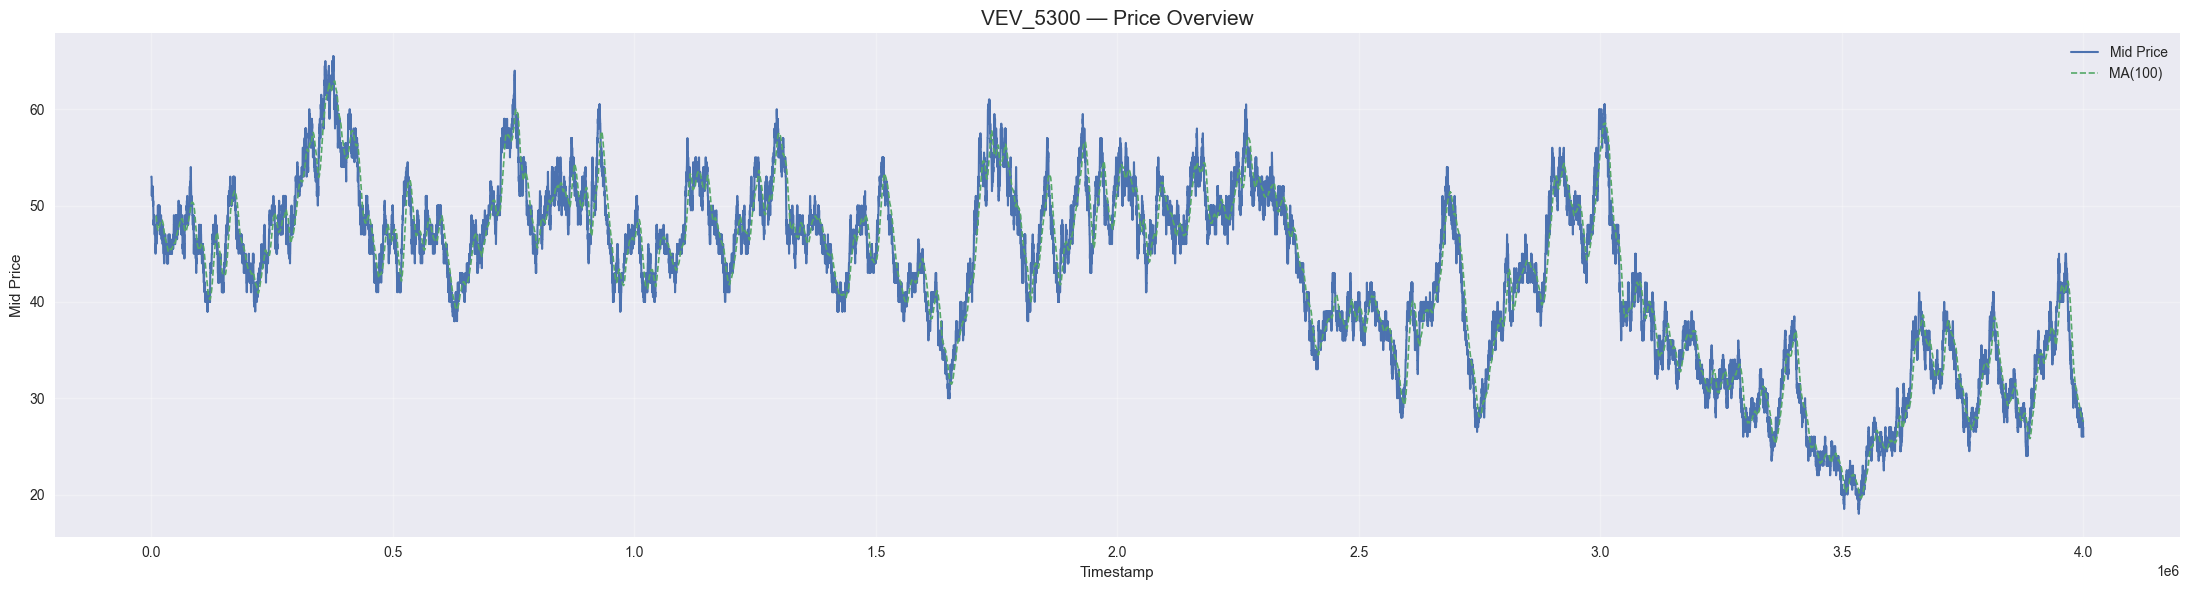

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,48.89,47.81,49.97
0,first half,49.18,48.09,50.26
0,second half,48.61,47.53,49.68
1,full day,46.91,45.85,47.96
1,first half,47.38,46.32,48.45
1,second half,46.44,45.39,47.48
2,full day,44.48,43.45,45.5
2,first half,47.41,46.35,48.47
2,second half,41.55,40.55,42.54
3,full day,32.14,31.26,33.02



VEV_5400


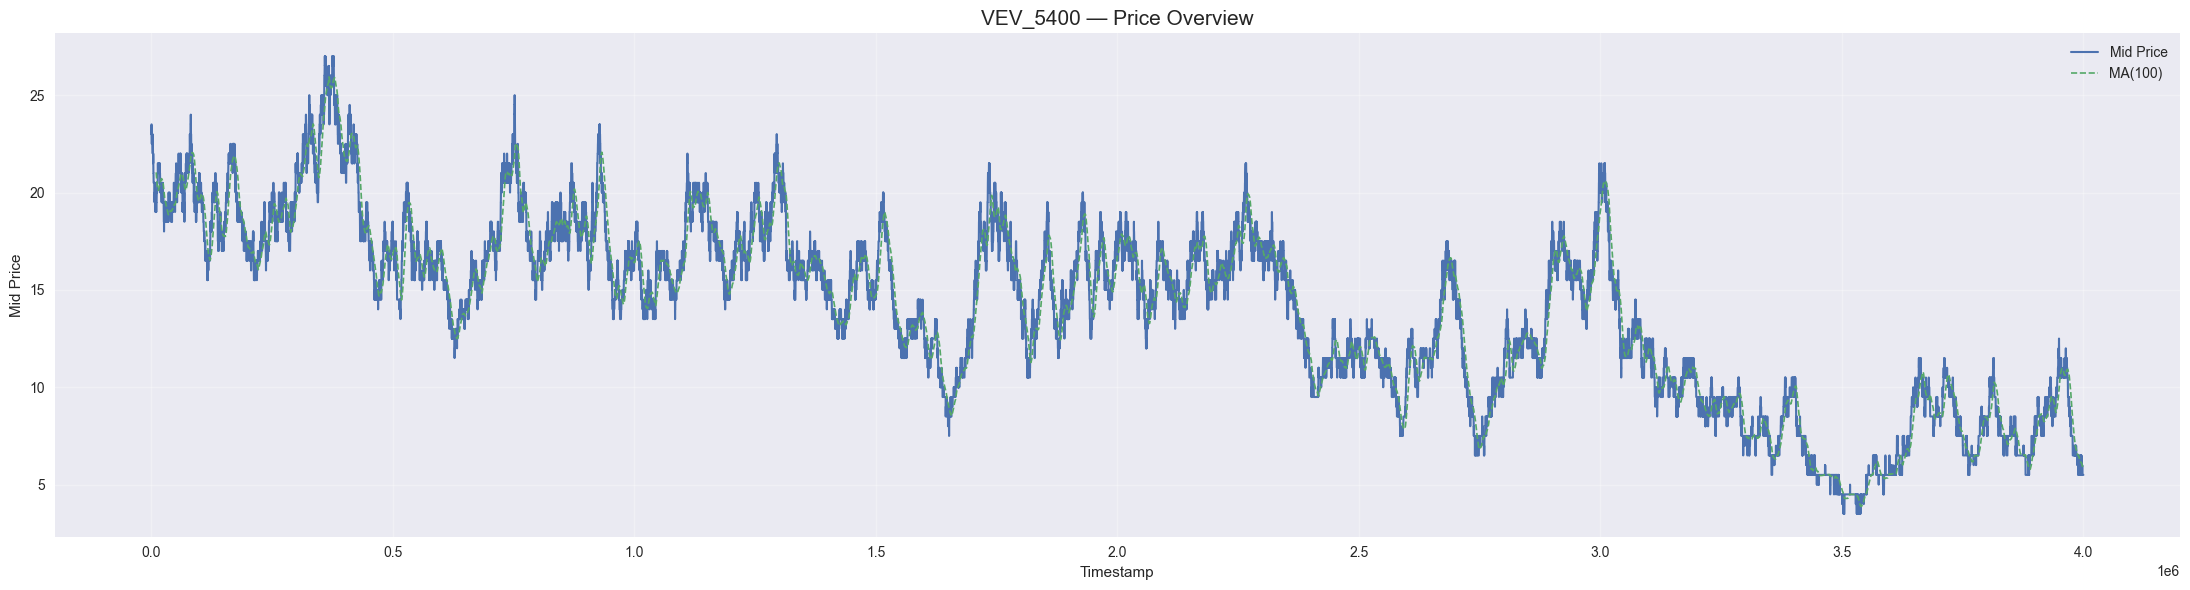

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,18.47,17.75,19.18
0,first half,19.79,19.06,20.52
0,second half,17.14,16.44,17.84
1,full day,15.65,14.96,16.35
1,first half,16.68,15.98,17.38
1,second half,14.63,13.94,15.31
2,full day,13.73,13.07,14.4
2,first half,15.03,14.34,15.72
2,second half,12.44,11.8,13.08
3,full day,8.5,7.9,9.1



VEV_5500


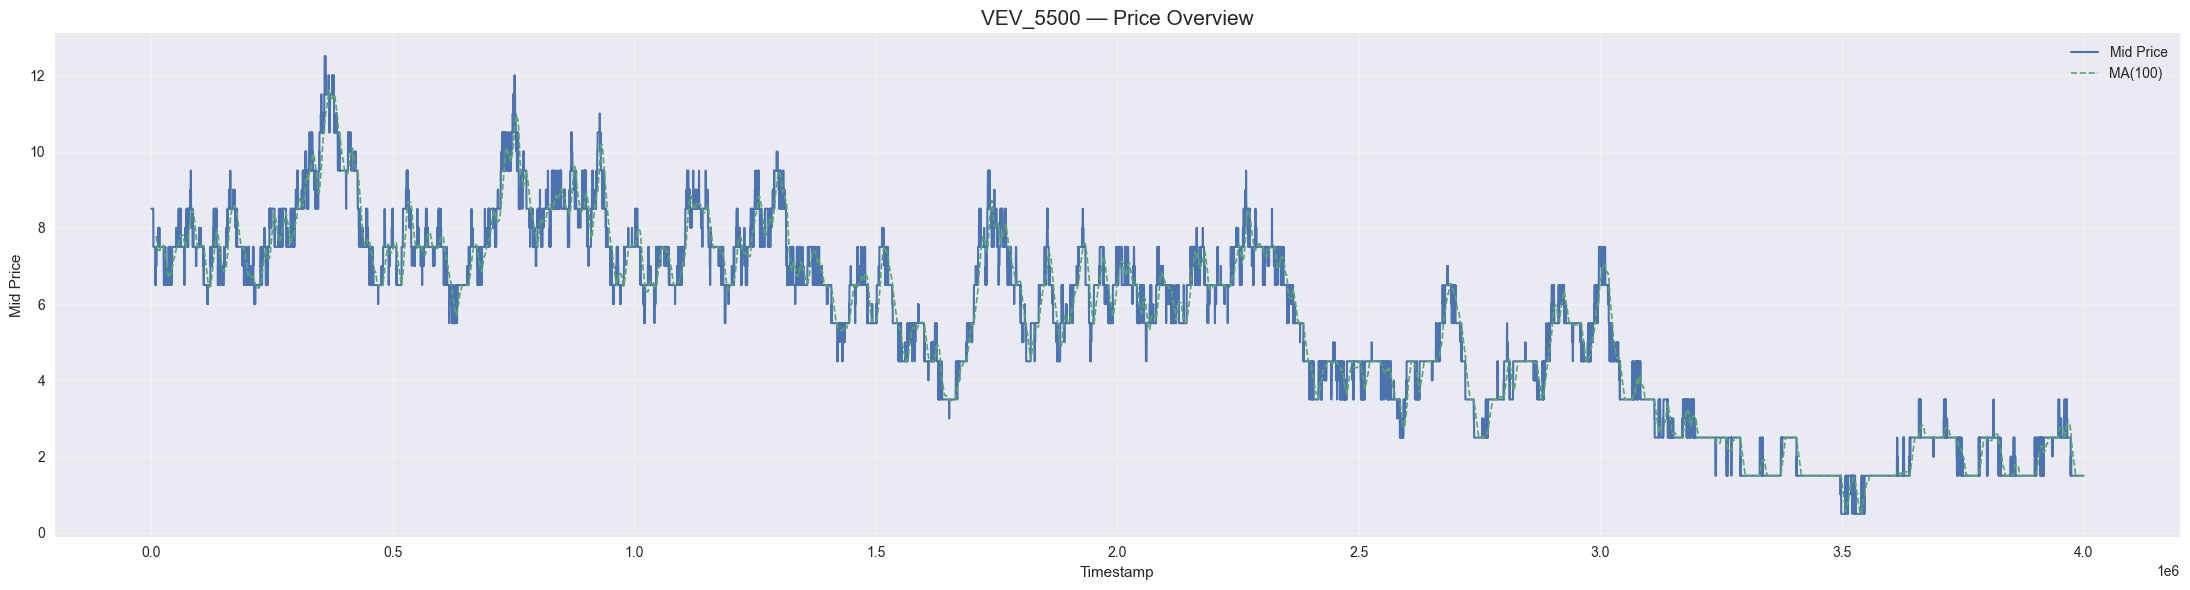

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,8.06,7.47,8.65
0,first half,8.09,7.5,8.68
0,second half,8.03,7.44,8.62
1,full day,6.57,5.99,7.15
1,first half,7.18,6.59,7.78
1,second half,5.96,5.39,6.52
2,full day,5.29,4.74,5.85
2,first half,6.09,5.52,6.67
2,second half,4.49,3.95,5.04
3,full day,2.26,1.73,2.79



VEV_6000


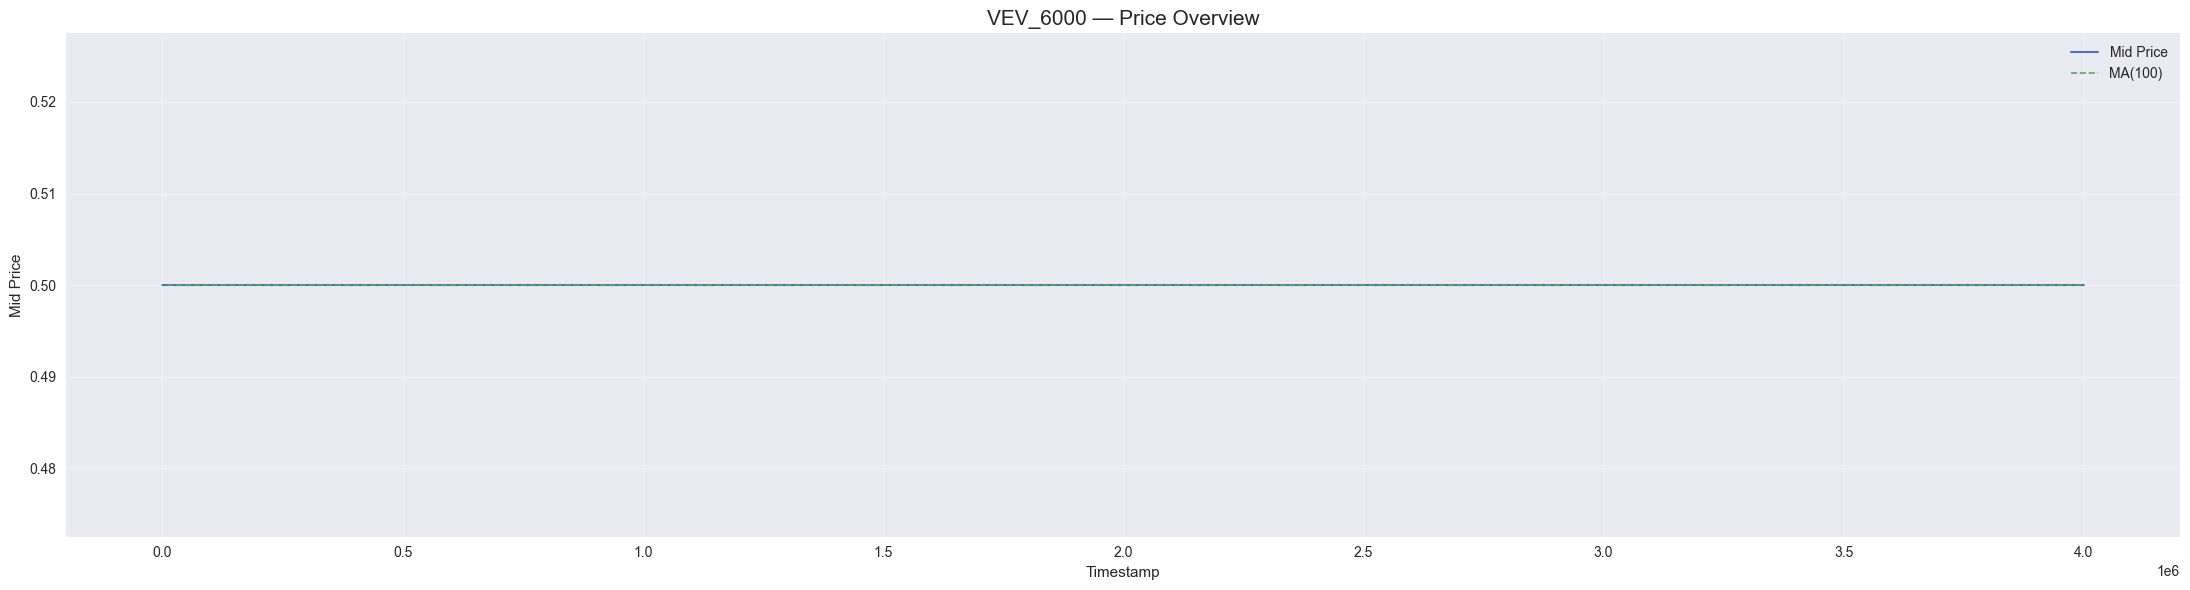

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,0.5,0.0,1.0
0,first half,0.5,0.0,1.0
0,second half,0.5,0.0,1.0
1,full day,0.5,0.0,1.0
1,first half,0.5,0.0,1.0
1,second half,0.5,0.0,1.0
2,full day,0.5,0.0,1.0
2,first half,0.5,0.0,1.0
2,second half,0.5,0.0,1.0
3,full day,0.5,0.0,1.0



VEV_6500


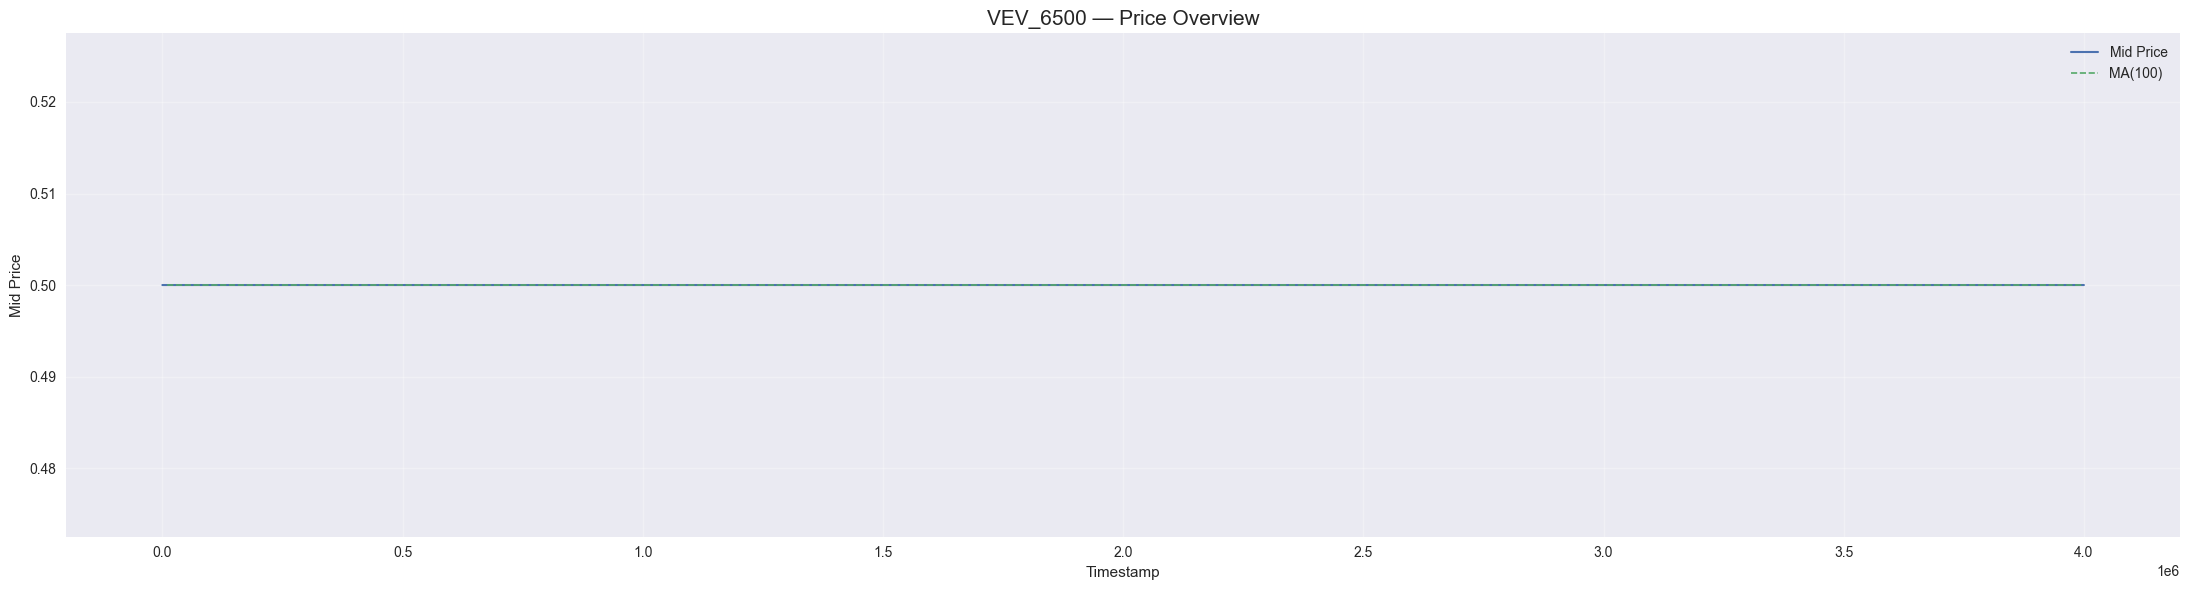

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,0.5,0.0,1.0
0,first half,0.5,0.0,1.0
0,second half,0.5,0.0,1.0
1,full day,0.5,0.0,1.0
1,first half,0.5,0.0,1.0
1,second half,0.5,0.0,1.0
2,full day,0.5,0.0,1.0
2,first half,0.5,0.0,1.0
2,second half,0.5,0.0,1.0
3,full day,0.5,0.0,1.0


In [7]:
# Price overview + fair values for full day / half-days using mid, best bid, best ask
overview(df, window=100)

In [8]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

df["mid"] = (df["bid_price_1"] + df["ask_price_1"]) / 2

# Robust sorting
sort_cols = []
if "day" in df.columns:
    sort_cols.append("day")
sort_cols += ["product", "timestamp"]

df = df.sort_values(sort_cols).copy()

# Compute returns WITHIN each product, and within each day if day exists
group_cols = ["product"]
if "day" in df.columns:
    group_cols = ["product", "day"]

df["log_mid"] = np.log(df["mid"])
df["log_ret"] = df.groupby(group_cols)["log_mid"].diff()

def plot_autocorrelation_correct(df, product, max_lag=30):
    d = df[df["product"] == product].dropna(subset=["log_ret"]).copy()
    r = d["log_ret"].values

    acf = []
    lags = range(1, max_lag + 1)

    for lag in lags:
        if len(r) > lag:
            acf.append(np.corrcoef(r[:-lag], r[lag:])[0, 1])
        else:
            acf.append(np.nan)

    fig = go.Figure()

    fig.add_trace(go.Bar(
        x=list(lags),
        y=acf,
        name="Return autocorrelation"
    ))

    fig.add_hline(y=0, line_dash="dash")

    fig.update_layout(
        title=f"{product} — Correct Return Autocorrelation",
        xaxis_title="Lag",
        yaxis_title="Autocorrelation",
        template="plotly_white",
        height=450
    )

    fig.show()

for product in get_products(df):
    if "VEV" in product:
        plot_autocorrelation_correct(df, product, max_lag=30)

.venv/lib/python3.9/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


.venv/lib/python3.9/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


In [12]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go



df["mid"] = (df["bid_price_1"] + df["ask_price_1"]) / 2

# Sort correctly
sort_cols = []
if "day" in df.columns:
    sort_cols.append("day")
sort_cols += ["product", "timestamp"]
df = df.sort_values(sort_cols).copy()

# Group by product and day, so returns do not jump across days
group_cols = ["product"]
if "day" in df.columns:
    group_cols = ["product", "day"]

df["log_mid"] = np.log(df["mid"])
df["ret"] = df.groupby(group_cols)["log_mid"].diff()
df["ret_lag1"] = df.groupby(group_cols)["ret"].shift(1)

def add_rolling_lag1_corr(df, window=500, min_periods=200):
    out = df.copy()

    def rolling_corr_one_group(g):
        g = g.copy()
        g["rolling_lag1_corr"] = (
            g["ret"]
            .rolling(window=window, min_periods=min_periods)
            .corr(g["ret_lag1"])
        )
        return g

    out = out.groupby(group_cols, group_keys=False).apply(rolling_corr_one_group)
    return out

df_corr = add_rolling_lag1_corr(df, window=500, min_periods=200)

def plot_lag1_corr_evolution(df_corr, product):
    d = df_corr[df_corr["product"] == product].copy()

    fig = go.Figure()

    if "day" in d.columns:
        for day, g in d.groupby("day"):
            fig.add_trace(go.Scatter(
                x=g["timestamp"],
                y=g["rolling_lag1_corr"],
                mode="lines",
                name=f"day {day}"
            ))
    else:
        fig.add_trace(go.Scatter(
            x=d["timestamp"],
            y=d["rolling_lag1_corr"],
            mode="lines",
            name=product
        ))

    fig.add_hline(y=0, line_dash="dash")
    fig.add_hline(y=-0.10, line_dash="dot")
    fig.add_hline(y=-0.20, line_dash="dot")

    fig.update_layout(
        title=f"{product} — Rolling Lag-1 Return Autocorrelation",
        xaxis_title="Timestamp",
        yaxis_title="Rolling corr(ret_t, ret_{t-1})",
        template="plotly_white",
        height=500
    )

    fig.show()


/var/folders/2g/43vdtj911db4ry8x4s1gy_jr0000gq/T/ipykernel_10256/2627582529.py:37: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = out.groupby(group_cols, group_keys=False).apply(rolling_corr_one_group)


In [13]:
for product in get_products(df_corr):
    if "VEV" in product:
        plot_lag1_corr_evolution(df_corr, product)

In [15]:


df["mid"] = (df["bid_price_1"] + df["ask_price_1"]) / 2

# Sort correctly
sort_cols = []
if "day" in df.columns:
    sort_cols.append("day")
sort_cols += ["product", "timestamp"]

df = df.sort_values(sort_cols).copy()

# Compute returns within each product/day
group_cols = ["product"]
if "day" in df.columns:
    group_cols = ["product", "day"]

df["log_mid"] = np.log(df["mid"])
df["ret"] = df.groupby(group_cols)["log_mid"].diff()
df["ret_lag1"] = df.groupby(group_cols)["ret"].shift(1)

def add_rolling_lag1_corr(df, window=500, min_periods=200):
    out = df.copy()

    def rolling_corr_one_group(g):
        g = g.copy()
        g["rolling_lag1_corr"] = (
            g["ret"]
            .rolling(window=window, min_periods=min_periods)
            .corr(g["ret_lag1"])
        )
        return g

    return out.groupby(group_cols, group_keys=False).apply(rolling_corr_one_group)

df_corr = add_rolling_lag1_corr(df, window=500, min_periods=200)

# Keep vouchers only
voucher_corr = df_corr[df_corr["product"].str.contains("VEV")].copy()

# Mean rolling lag-1 autocorr per voucher per day
mean_autocorr_by_day = (
    voucher_corr
    .groupby(["product", "day"])["rolling_lag1_corr"]
    .mean()
    .reset_index()
    .rename(columns={"rolling_lag1_corr": "mean_rolling_lag1_autocorr"})
)

# Pivot table: rows = vouchers, columns = days
mean_autocorr_table = mean_autocorr_by_day.pivot(
    index="product",
    columns="day",
    values="mean_rolling_lag1_autocorr"
)

mean_autocorr_table

/var/folders/2g/43vdtj911db4ry8x4s1gy_jr0000gq/T/ipykernel_10256/1301389950.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return out.groupby(group_cols, group_keys=False).apply(rolling_corr_one_group)


day,0,1,2,3
product,,,,
VEV_4000,-0.273754,-0.284609,-0.281783,-0.304143
VEV_4500,-0.215778,-0.228239,-0.218612,-0.244129
VEV_5000,-0.095221,-0.110488,-0.091694,-0.110741
VEV_5100,-0.090750,-0.105300,-0.088226,-0.101177
VEV_5200,-0.143880,-0.150998,-0.111655,-0.116571
VEV_5300,-0.205696,-0.223631,-0.209817,-0.217215
VEV_5400,-0.266306,-0.263877,-0.225356,-0.245130
VEV_5500,-0.253597,-0.240281,-0.227236,-0.220634
VEV_6000,NaN,NaN,NaN,NaN


In [16]:
direct_autocorr_by_day = (
    voucher_corr
    .dropna(subset=["ret", "ret_lag1"])
    .groupby(["product", "day"])
    .apply(lambda g: g["ret"].corr(g["ret_lag1"]))
    .reset_index(name="direct_daily_lag1_autocorr")
)

direct_autocorr_table = direct_autocorr_by_day.pivot(
    index="product",
    columns="day",
    values="direct_daily_lag1_autocorr"
)

direct_autocorr_table

.venv/lib/python3.9/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/var/folders/2g/43vdtj911db4ry8x4s1gy_jr0000gq/T/ipykernel_10256/2907630419.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  voucher_corr


day,0,1,2,3
product,,,,
VEV_4000,-0.279483,-0.287369,-0.286111,-0.308792
VEV_4500,-0.220457,-0.232327,-0.222183,-0.246442
VEV_5000,-0.097298,-0.110227,-0.090688,-0.109446
VEV_5100,-0.094761,-0.106264,-0.092754,-0.100325
VEV_5200,-0.146377,-0.149401,-0.110845,-0.115485
VEV_5300,-0.215295,-0.227152,-0.216709,-0.217204
VEV_5400,-0.269638,-0.266892,-0.226034,-0.245679
VEV_5500,-0.259597,-0.246979,-0.230396,-0.180107
VEV_6000,NaN,NaN,NaN,NaN


In [10]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

df["mid"] = (df["bid_price_1"] + df["ask_price_1"]) / 2

sort_cols = []
if "day" in df.columns:
    sort_cols.append("day")
sort_cols += ["product", "timestamp"]
df = df.sort_values(sort_cols).copy()

group_cols = ["product"]
if "day" in df.columns:
    group_cols = ["product", "day"]

df["log_mid"] = np.log(df["mid"])
df["ret_1"] = df.groupby(group_cols)["log_mid"].diff()

def analyse_zscore_predictiveness(df, product, window=100, horizons=[1, 2, 5, 10]):
    d = df[df["product"] == product].copy()

    d["rolling_mean"] = d.groupby("day")["mid"].transform(
        lambda x: x.rolling(window, min_periods=window).mean()
    ) if "day" in d.columns else d["mid"].rolling(window, min_periods=window).mean()

    d["rolling_std"] = d.groupby("day")["mid"].transform(
        lambda x: x.rolling(window, min_periods=window).std()
    ) if "day" in d.columns else d["mid"].rolling(window, min_periods=window).std()

    d["zscore"] = (d["mid"] - d["rolling_mean"]) / d["rolling_std"]

    rows = []

    for h in horizons:
        if "day" in d.columns:
            d[f"future_ret_{h}"] = d.groupby("day")["log_mid"].shift(-h) - d["log_mid"]
        else:
            d[f"future_ret_{h}"] = d["log_mid"].shift(-h) - d["log_mid"]

        clean = d.dropna(subset=["zscore", f"future_ret_{h}"])

        corr = clean["zscore"].corr(clean[f"future_ret_{h}"])

        rows.append({
            "product": product,
            "window": window,
            "horizon": h,
            "corr(zscore, future_return)": corr
        })

    return pd.DataFrame(rows)

all_results = []

for product in get_products(df):
    if "VEV" in product:
        all_results.append(analyse_zscore_predictiveness(df, product, window=100))

zscore_results = pd.concat(all_results, ignore_index=True)
zscore_results

,product,window,horizon,"corr(zscore, future_return)"
0,VEV_4000,100,1,-0.090630
1,VEV_4000,100,2,-0.076456
2,VEV_4000,100,5,-0.055086
3,VEV_4000,100,10,-0.039851
4,VEV_4500,100,1,-0.064433
5,VEV_4500,100,2,-0.052620
6,VEV_4500,100,5,-0.036127
7,VEV_4500,100,10,-0.025161
8,VEV_5000,100,1,-0.024755
9,VEV_5000,100,2,-0.019248
